Read Data

In [3]:
import pandas as pd


In [4]:
df = pd.read_csv('D:\COMSCI_3rd_year\CP463\Lab-19-10-69\data\churn_synthetic.csv')
display(df)

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\Bhakin31\AppData\Local\Temp\ipykernel_26592\4040291705.py:1: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\COMSCI_3rd_year\CP463\Lab-19-10-69\data\churn_synthetic.csv')


,customer_id,monthly_usage_hours,tenure_months,support_tickets,subscription_type,churn
0,1,18.2,55,1,Premium,0
1,2,23.3,31,1,Basic,0
2,3,31.6,25,0,Basic,0
3,4,1.9,54,1,Premium,0
4,5,19.3,28,2,Standard,0
...,...,...,...,...,...,...
995,996,47.0,55,1,Basic,0
996,997,28.2,30,5,Standard,1
997,998,33.7,33,1,Basic,0
998,999,10.6,33,1,Standard,0


In [5]:
X_num = df[['monthly_usage_hours','tenure_months','support_tickets']]
X_cat = pd.get_dummies(df['subscription_type'],dtype = float)
X_cat.head()

,Basic,Premium,Standard
0,0.0,1.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,1.0,0.0
4,0.0,0.0,1.0


In [6]:
X_cat.drop('Basic',axis = 1,inplace =True)
X_cat.head()

,Premium,Standard
0,1.0,0.0
1,0.0,0.0
2,0.0,0.0
3,1.0,0.0
4,0.0,1.0


In [7]:
#Merge X_num,X_cat
X = pd.concat([X_num,X_cat],axis  =1)
X.head()

,monthly_usage_hours,tenure_months,support_tickets,Premium,Standard
0,18.2,55,1,1.0,0.0
1,23.3,31,1,0.0,0.0
2,31.6,25,0,0.0,0.0
3,1.9,54,1,1.0,0.0
4,19.3,28,2,0.0,1.0


In [8]:
y = df['churn']
y.head()

0    0
1    0
2    0
3    0
4    0
Name: churn, dtype: int64

In [9]:
dataset = pd.concat([X,y],axis = 1)

#Data Splitting 

In [10]:
%pip install scikit-learn
from sklearn.model_selection import train_test_split

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [20]:
train, remain = train_test_split(
    df, test_size=0.3, random_state=256, stratify=df['churn']
)
test, val = train_test_split(
    remain, test_size=0.5, random_state=256, stratify=remain['churn']
)

In [21]:
import matplotlib.pyplot as plt


Text(0.5, 1.0, 'Test Distribution')

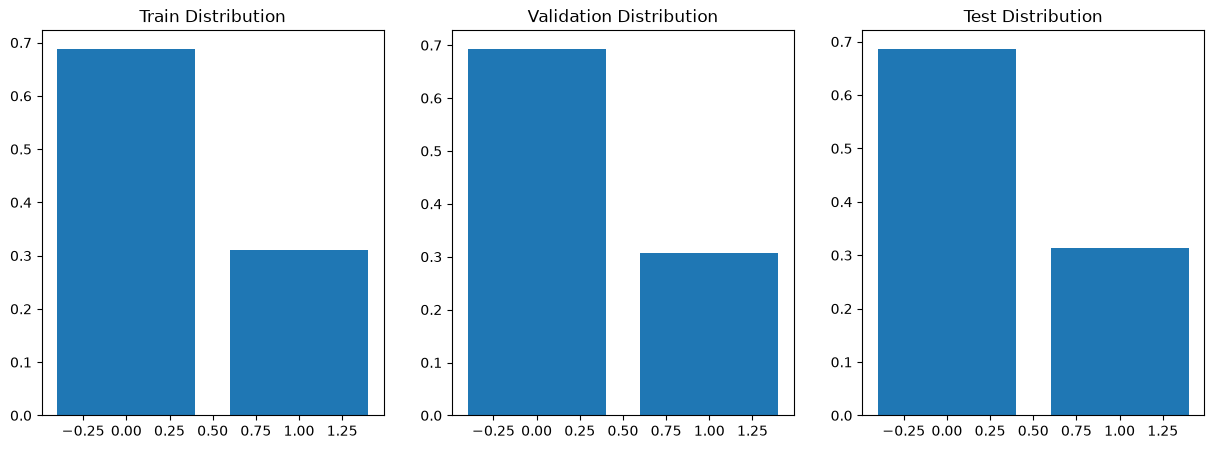

In [22]:
train_dist = train['churn'].value_counts(normalize=True)
val_dist = val['churn'].value_counts(normalize=True)
test_dist = test['churn'].value_counts(normalize=True)

fig,ax = plt.subplots(1,3,figsize = (15,5))
ax[0].bar(train_dist.index,train_dist.values)
ax[0].set_title('Train Distribution')
ax[1].bar(val_dist.index,val_dist.values)
ax[1].set_title('Validation Distribution')
ax[2].bar(test_dist.index,test_dist.values)
ax[2].set_title('Test Distribution')


Modeling

In [16]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight='balanced', random_state=256,verbose = 1,solver = 'lbfgs',max_iter=1000)

In [17]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

compute_class_weight(class_weight='balanced', classes=np.array([0,1]), y=train['churn'])


array([0.72614108, 1.60550459])

generate the list of parameter C

In [23]:
import numpy as np
from scipy.stats import uniform

np.random.seed(256)
rd_hparams = dict(
    C = uniform(loc=0,scale=5))

0.22891900816548572


random search CV

In [46]:
from sklearn.model_selection import RandomizedSearchCV
rand_tune = RandomizedSearchCV(model,rd_hparams,
                               scoring = 'roc_auc',
                               n_iter = 100,
                               random_state=256,
                               cv=[[train.index, val.index]] )  # cv = 5 use this if you want to use k-fold cross validation
                                #cv=[[train_index, val_index]] use this if you want to use your own train/val split
                                
rand_search = rand_tune.fit(X,y)

In [47]:
train.head()

,customer_id,monthly_usage_hours,tenure_months,support_tickets,subscription_type,churn
991,992,31.4,48,2,Premium,0
864,865,20.4,45,1,Standard,0
713,714,32.3,3,2,Standard,0
906,907,9.0,38,2,Basic,0
385,386,7.2,34,0,Basic,1


Making a grid search for the parameter C

In [49]:
C = [rand_search.best_estimator_.C + 0.05 * i for i in range(-5,6)]
gd_hparams = {'C':[i if i>0 else 0.001 for i in C]}

In [51]:
gd_hparams


{'C': [0.001,
  0.001,
  0.001,
  0.001,
  np.float64(0.019968024999898512),
  np.float64(0.06996802499989851),
  np.float64(0.11996802499989852),
  np.float64(0.16996802499989852),
  np.float64(0.21996802499989854),
  np.float64(0.2699680249998985),
  np.float64(0.3199680249998985)]}

Grid Search Cross validation

In [73]:
from sklearn.model_selection import GridSearchCV
optimal_model = LogisticRegression(class_weight='balanced', 
                                   random_state=256,
                                   verbose = 1,
                                   solver = 'lbfgs',
                                   max_iter=1000)
grid_tune = GridSearchCV(optimal_model, gd_hparams,
                         scoring = 'roc_auc',
                         cv=[[train.index, val.index]],
                         refit=False)
grid_search = grid_tune.fit(X,y)

Prediction

In [75]:
from sklearn.base import clone
best_model = clone(grid_search.estimator).set_params(**grid_search.best_params_)
fit_index = train.index.union(val.index)
best_model.fit(X.loc[fit_index], y.loc[fit_index])
probs = best_model.predict_proba(X.loc[test.index])

In [76]:
probs

array([[0.36185891, 0.63814109],
       [0.1231473 , 0.8768527 ],
       [0.24919576, 0.75080424],
       [0.64928249, 0.35071751],
       [0.29775837, 0.70224163],
       [0.91346558, 0.08653442],
       [0.23310952, 0.76689048],
       [0.3733243 , 0.6266757 ],
       [0.18590551, 0.81409449],
       [0.38507685, 0.61492315],
       [0.30646458, 0.69353542],
       [0.48811381, 0.51188619],
       [0.48822403, 0.51177597],
       [0.46558256, 0.53441744],
       [0.33575599, 0.66424401],
       [0.60041357, 0.39958643],
       [0.5548958 , 0.4451042 ],
       [0.78907186, 0.21092814],
       [0.93814031, 0.06185969],
       [0.45228424, 0.54771576],
       [0.37334919, 0.62665081],
       [0.39217609, 0.60782391],
       [0.32467537, 0.67532463],
       [0.76081741, 0.23918259],
       [0.3945899 , 0.6054101 ],
       [0.51286579, 0.48713421],
       [0.64159134, 0.35840866],
       [0.17570538, 0.82429462],
       [0.31568329, 0.68431671],
       [0.6221431 , 0.3778569 ],
       [0.

In [77]:
yhat = best_model.predict(X.loc[test.index])

In [78]:
yhat

array([1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0])

In [79]:
from sklearn.metrics import roc_curve
fpr, tpr, cutoffs = roc_curve(
    y_true=y.loc[test.index],
    y_score=probs[:, 1],
    pos_label=1
)

In [80]:
temp = pd.DataFrame({'fpr': fpr, 'tpr': tpr, 'cutoffs': cutoffs})
idx = np.argmax(tpr - fpr)
c =cutoffs[idx]
print(f"Optimal cutoff: {c}")

Optimal cutoff: 0.44243017427774967


Predict label

In [81]:
yhat = (probs[:,1] >= c).astype(int)

Evaluation

In [82]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
precision = precision_score(y.loc[test.index], yhat)
recall = recall_score(y.loc[test.index], yhat)
f1 = f1_score(y.loc[test.index], yhat)
accuracy = accuracy_score(y.loc[test.index], yhat)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")


Precision: 0.5000
Recall: 0.8723
F1 Score: 0.6357
Accuracy: 0.6867


C:\Users\Bhakin31\AppData\Local\Temp\ipykernel_26592\794517197.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([0,1],[0,1],'k--',linewidth = 0.5,color = 'gray')


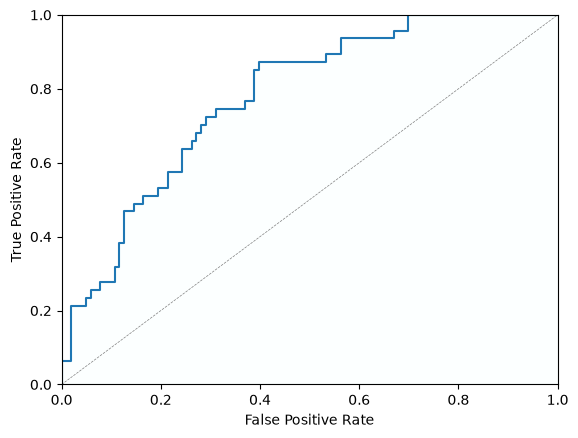

In [84]:
from sklearn.metrics import roc_auc_score
aucroc = roc_auc_score(y_true=y[test.index], y_score = probs[:, 1])
fpr,tpr, _  = roc_curve(y_true=y[test.index], y_score = probs[:, 1],pos_label =1)
plt.plot(fpr,tpr, label =f"AUC = {aucroc:.4f}")
plt.plot([0,1],[0,1],'k--',linewidth = 0.5,color = 'gray')
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title
plt.fill_between(fpr,tpr,alpha = 0.2,color = 'azure')
plt.show()